In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
  return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

In [4]:
xs = np.arange(-5, 5, 0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [5]:
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

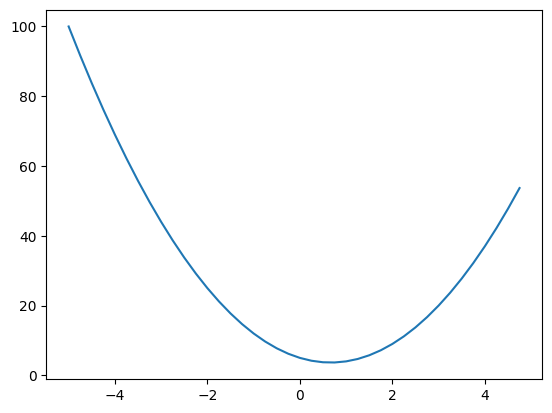

In [6]:
plt.plot(xs, ys)

In [7]:
h = 0.001
x = 3.0
(f(x + h) - f(x))/h

14.00300000000243

In [8]:
h = 0.000001
x = 2/3
(f(x + h) - f(x))/h

2.999378523327323e-06

In [9]:
# Lets get more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [10]:
h = 0.001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c

print('d1 ', d1)
print('d2 ', d2)
print('Slope ', (d2 - d1)/h)

d1  4.0
d2  4.0009999999999994
Slope  0.9999999999994458


In [11]:
h = 0.001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print('d1 ', d1)
print('d2 ', d2)
print('Slope ', (d2 - d1)/h)

d1  4.0
d2  3.997
Slope  -3.0000000000001137


In [12]:
h = 0.001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
b += h
d2 = a*b + c

print('d1 ', d1)
print('d2 ', d2)
print('Slope ', (d2 - d1)/h)

d1  4.0
d2  4.002
Slope  1.9999999999997797


In [13]:
class Value:
  def __init__(self, data, children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda : None
    self._prev = set(children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out  = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad

    out._backward = _backward
    return out

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "supports only int and float powers"
    out = Value(self.data**other, (self, ), f'**{other}')

    def _backward():
      self.grad += other * (self.data**(other - 1)) * out.grad

    out._backward = _backward
    return out

  def __rmul__(self, other):
    return self * other

  def __radd__(self, other):
    return self + other

  def __neg__(self):
    return self * -1

  def __sub__(self, other):
    return self + (-other)

  def __truediv__(self, other):
    return self * other**-1

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad

    out._backward = _backward
    return out

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad += out.data * out.grad

    out._backward = _backward
    return out

  def backward(self):
    topo = []
    visited = set()

    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0

    for node in reversed(topo):
      node._backward()

In [14]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b
e.label = 'e'
d = e + c
d.label = 'd'
# d = a*b + c => (a.__mul__(b)).__add__(c)
print('d ', d)
print('d._prev ', d._prev)
print('d._op ', d._op)
f = Value(2.0, label='f')
L = d * f
L.label = 'L'
print('L ', L)
print('L._prev ', L._prev)
print('L._op ', L._op)


print('L._backward ', L._backward)

d  Value(data=4.0)
d._prev  {Value(data=-6.0), Value(data=10.0)}
d._op  +
L  Value(data=8.0)
L._prev  {Value(data=4.0), Value(data=2.0)}
L._op  *
L._backward  <function Value.__mul__.<locals>._backward at 0x7bde45bb5580>


In [15]:
from graphviz import Digraph

def trace(root):
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # if any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

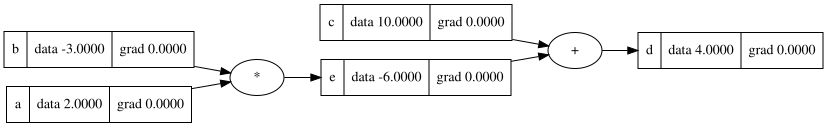

In [16]:
draw_dot(d)

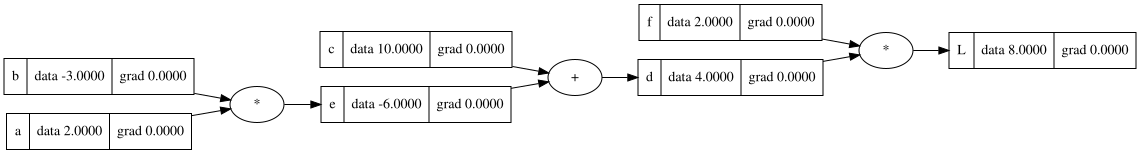

In [17]:
draw_dot(L)

In [18]:
def manual_derivative():
  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b
  e.label = 'e'
  d = e + c
  d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f
  L.label = 'L'
  L1 = L.data

  # Find derivative of L manually wrt different inputs and populate it for the draw_dot
  h = 0.001

  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  a.data += h
  # b.data += h
  c = Value(10.0, label='c')
  # c.data += h
  e = a*b
  # e.data += h
  e.label = 'e'
  d = e + c
  # d.data += h
  d.label = 'd'
  f = Value(-2.0, label='f')
  # f.data += h
  L = d * f
  L.label = 'L'


  L2 = L.data

  print((L2 - L1)/h)

manual_derivative()

6.000000000000227


In [19]:
a.grad = 6.0
b.grad = -4.0
c.grad = -2.0
e.grad = -2.0
d.grad = -2.0
f.grad = 4.0
L.grad = 1.0

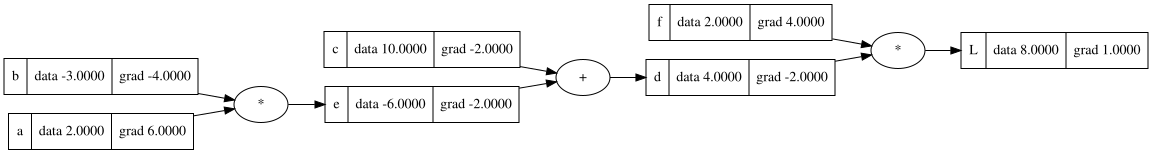

In [20]:
draw_dot(L)

In [21]:
## Manual Back Propagation example 2 : a NEURON

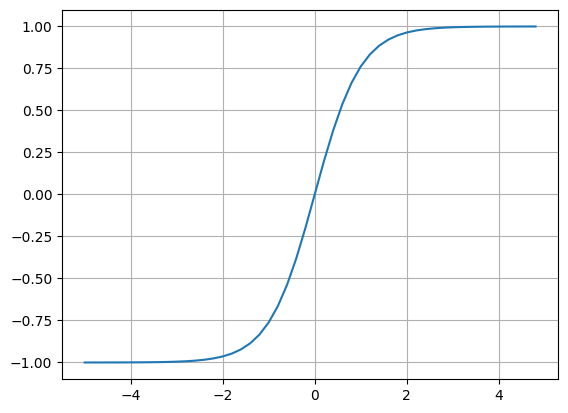

In [22]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)));
plt.grid();
# Activation Function

In [23]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias of the Neuron
b = Value(6.8813735870295432, label='b')

# w1x1 + w2x2 + b
w1x1 = w1*x1; w1x1.label='w1*x1'
w2x2 = w2*x2; w2x2.label='w2*x2'
w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label='w1*x1 + w2*x2'
n = w1x1w2x2 + b; n.label='n'
o = n.tanh(); o.label='o'

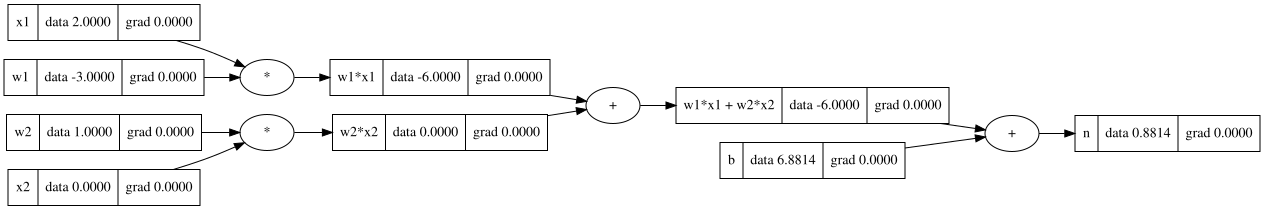

In [24]:
draw_dot(n)

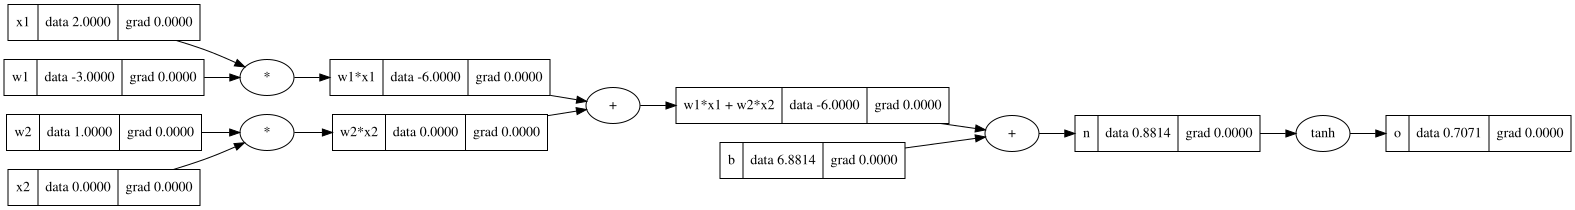

In [25]:
draw_dot(o)

In [26]:
o.grad = 1.0

In [27]:
o._backward()

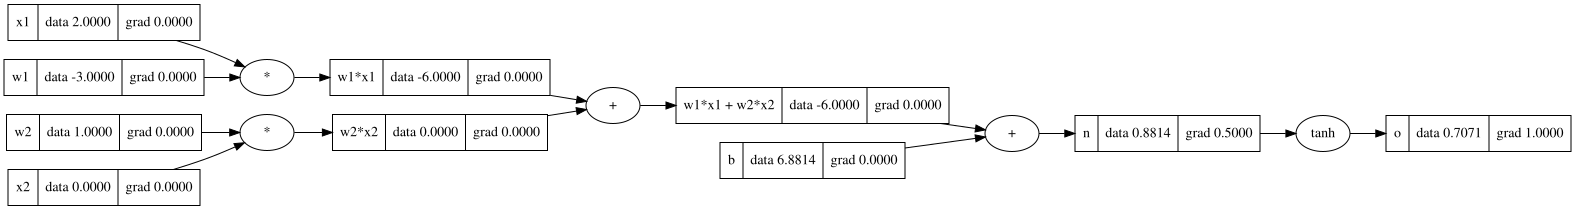

In [28]:
draw_dot(o)

In [29]:
n._backward()

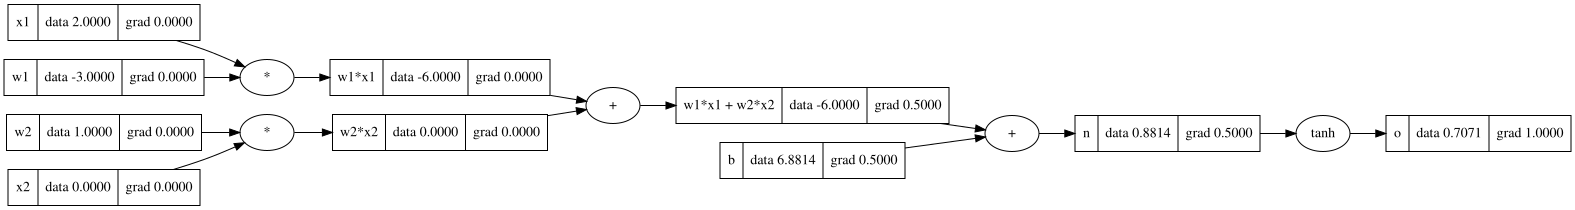

In [30]:
draw_dot(o)

In [31]:
b._backward()
w1x1w2x2._backward()

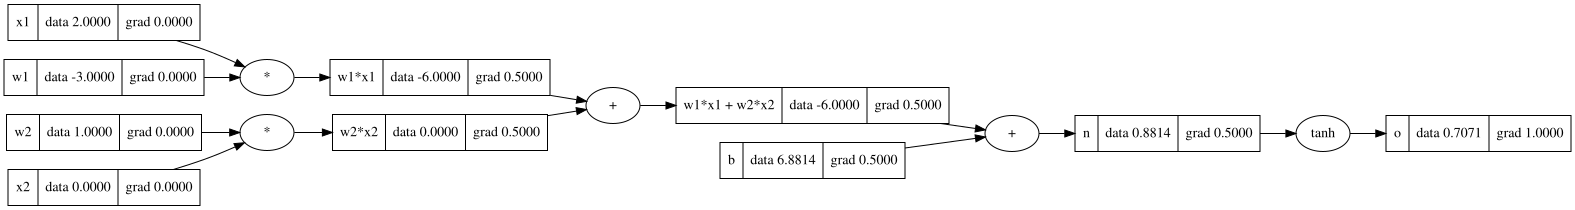

In [32]:
draw_dot(o)

In [33]:
w1x1._backward()
w2x2._backward()

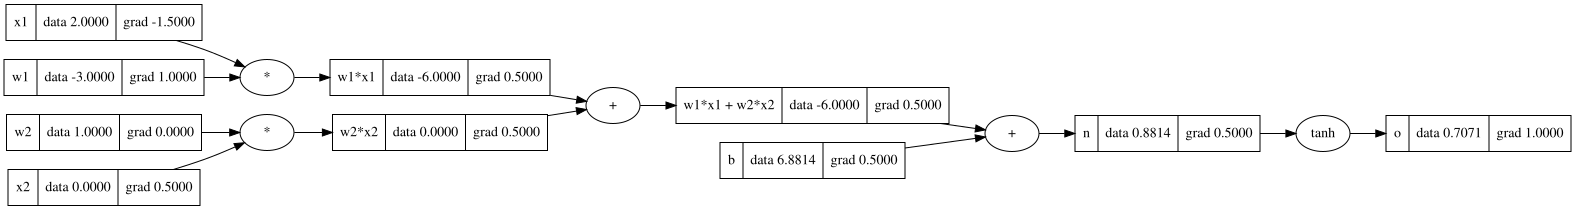

In [34]:
draw_dot(o)

In [35]:
topo = []
visited = set()

def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)

build_topo(o)

In [36]:
topo

[Value(data=6.881373587029543),
 Value(data=2.0),
 Value(data=-3.0),
 Value(data=-6.0),
 Value(data=0.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=0.8813735870295432),
 Value(data=0.7071067811915476)]

In [37]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias of the Neuron
b = Value(6.8813735870295432, label='b')

# w1x1 + w2x2 + b
w1x1 = w1*x1; w1x1.label='w1*x1'
w2x2 = w2*x2; w2x2.label='w2*x2'
w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label='w1*x1 + w2*x2'
n = w1x1w2x2 + b; n.label='n'
o = n.tanh(); o.label='o'

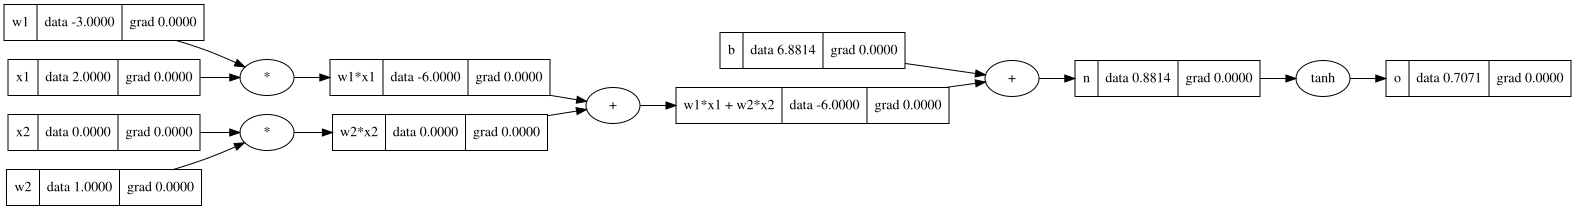

In [38]:
draw_dot(o)

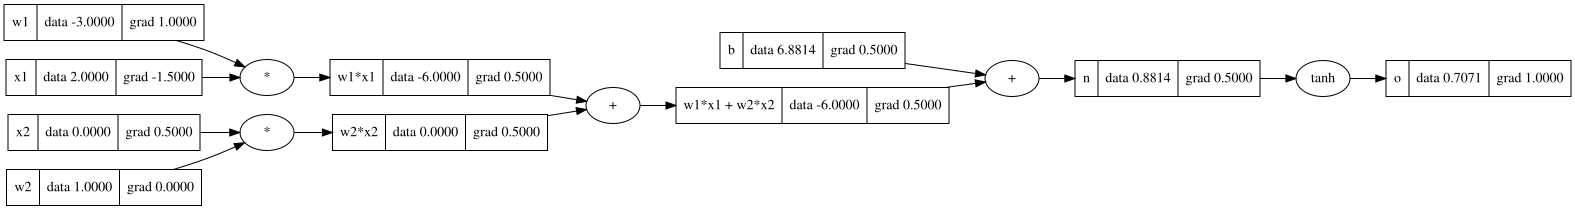

In [39]:
o.backward()
draw_dot(o)

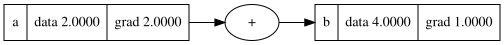

In [40]:
a = Value(2.0, label='a')
b = a + a; b.label='b'

b.backward()
draw_dot(b)

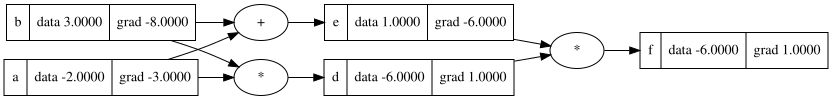

In [41]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a*b; d.label='d'
e = a + b; e.label='e'
f = d*e; f.label='f'

f.backward()
draw_dot(f)

In [42]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# Weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# Bias of the Neuron
b = Value(6.8813735870295432, label='b')

# w1x1 + w2x2 + b
w1x1 = w1*x1; w1x1.label='w1*x1'
w2x2 = w2*x2; w2x2.label='w2*x2'
w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label='w1*x1 + w2*x2'
n = w1x1w2x2 + b; n.label='n'
# -------
e = (2*n).exp()
o = (e - 1)/(e + 1)
o.label='o'

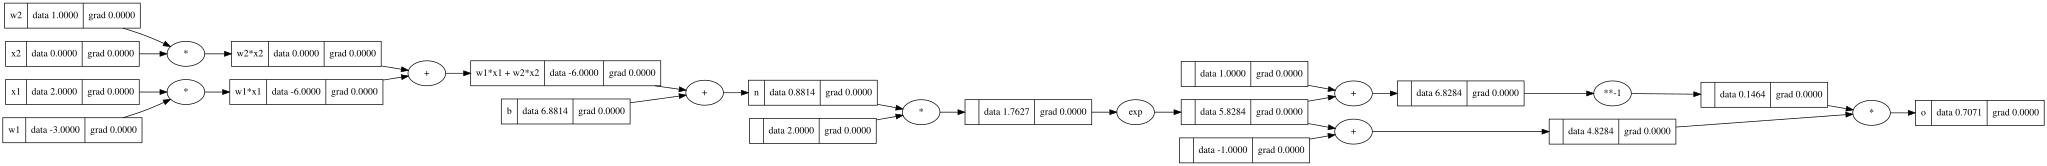

In [43]:
draw_dot(o)

In [44]:
o.backward()

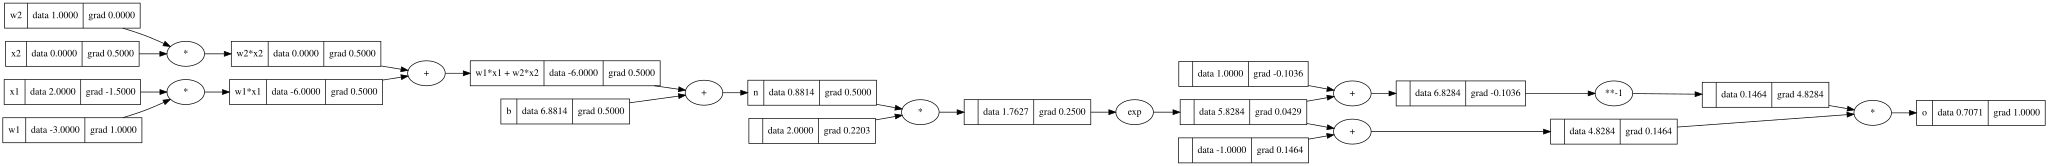

In [45]:
draw_dot(o)

Doing the same thing but in PyTorch


In [59]:
import torch
import random

In [60]:
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.8813735870295432]).double(); b.requires_grad = True

print(x1.item())

n = w1*x1 + w2*x2 + b
o = torch.tanh(n)

2.0


In [61]:
print(o.item())
print(o.data.item())
print('----')
o.backward()
print(x1.grad.item())
print(w1.grad.item())
print(x2.grad.item())
print(w2.grad.item())

0.7071066904050358
0.7071066904050358
----
-1.5000003851533106
1.0000002567688737
0.5000001283844369
0.0


In [116]:
class Neuron:
  def __init__(self, nin):
    self.weights = [Value(random.uniform(-1, 1)) for _ in range(nin)]
    self.bias = Value(random.uniform(-1, 1))

  def __call__(self, x):
    n = sum((wi*ni for wi, ni in zip(self.weights, x)) , self.bias)
    out = n.tanh()
    return out

  def parameters(self):
    return self.weights + [self.bias]

class Layer:
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for Layer in self.layers for p in Layer.parameters()]

Value(data=0.7145433900246403)
---
length of parameters:  4
---
parameters:  [Value(data=-0.6603872053227222), Value(data=0.4160698147541593), Value(data=-0.40071490593041514), Value(data=0.5682560808482793)]


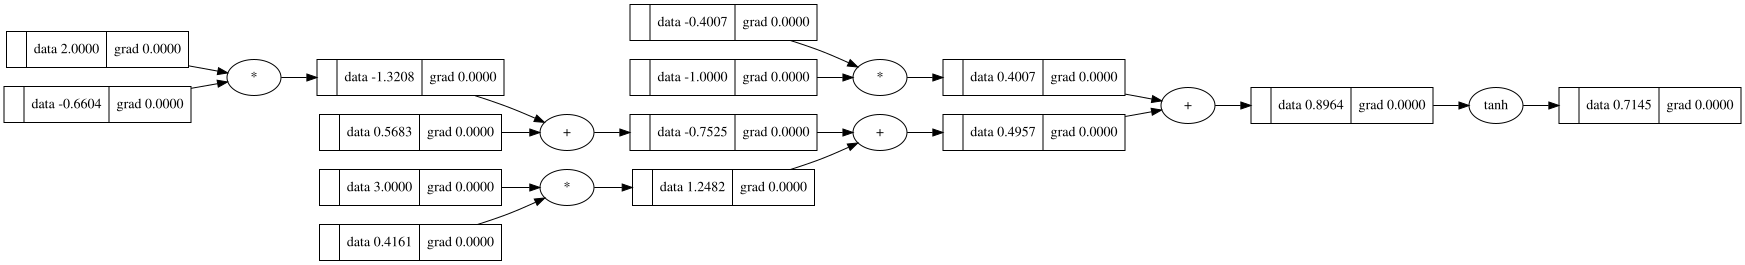

In [117]:
x = [2.0, 3.0, -1.0]
n = Neuron(3)
n(x)
print(n(x))
print('---')
print('length of parameters: ', len(n.parameters()))
print('---')
print('parameters: ', n.parameters())
draw_dot(n(x))

Value(data=-0.9636857674344417)
---
length of parameters:  4
---
parameters:  [Value(data=-0.9840520742959169), Value(data=-0.5402345317628137), Value(data=-0.8262818438540387), Value(data=0.7673415331380731)]


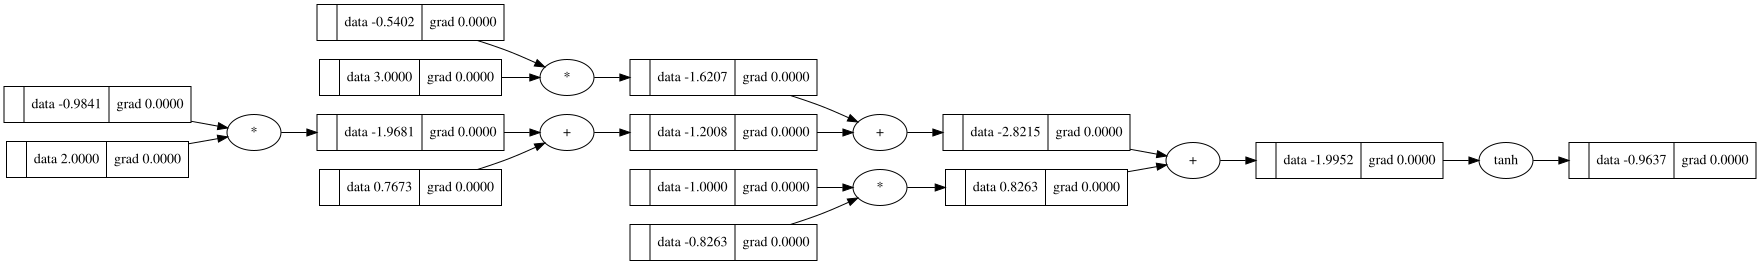

In [118]:
x = [2.0, 3.0, -1.0]
n = Layer(3, 1)
n(x)
print(n(x))
print('---')
print('length of parameters: ', len(n.parameters()))
print('---')
print('parameters: ', n.parameters())
draw_dot(n(x))

Value(data=-0.980415915497201)
---
length of parameters:  41
---
parameters:  [Value(data=0.24022537449316084), Value(data=0.9536980906145067), Value(data=-0.01215968384498467), Value(data=-0.46917409408793165), Value(data=0.3161534311290859), Value(data=0.47637807601583426), Value(data=0.6242835521167518), Value(data=-0.7436429832108047), Value(data=0.8686862119873762), Value(data=0.20202805216252062), Value(data=0.6942713633325439), Value(data=0.3129981313996273), Value(data=0.9258894779210398), Value(data=-0.6796063360666378), Value(data=0.08927112704344209), Value(data=-0.8731278545973067), Value(data=-0.8170175297747739), Value(data=-0.6220530660402712), Value(data=0.33664217818426634), Value(data=0.17263975058512226), Value(data=0.3978428986192468), Value(data=-0.8651720368391531), Value(data=0.8445443890186808), Value(data=0.00011840266508111874), Value(data=-0.5417860889068518), Value(data=0.5997839528736388), Value(data=-0.47293362806680306), Value(data=-0.2787754302546548), V

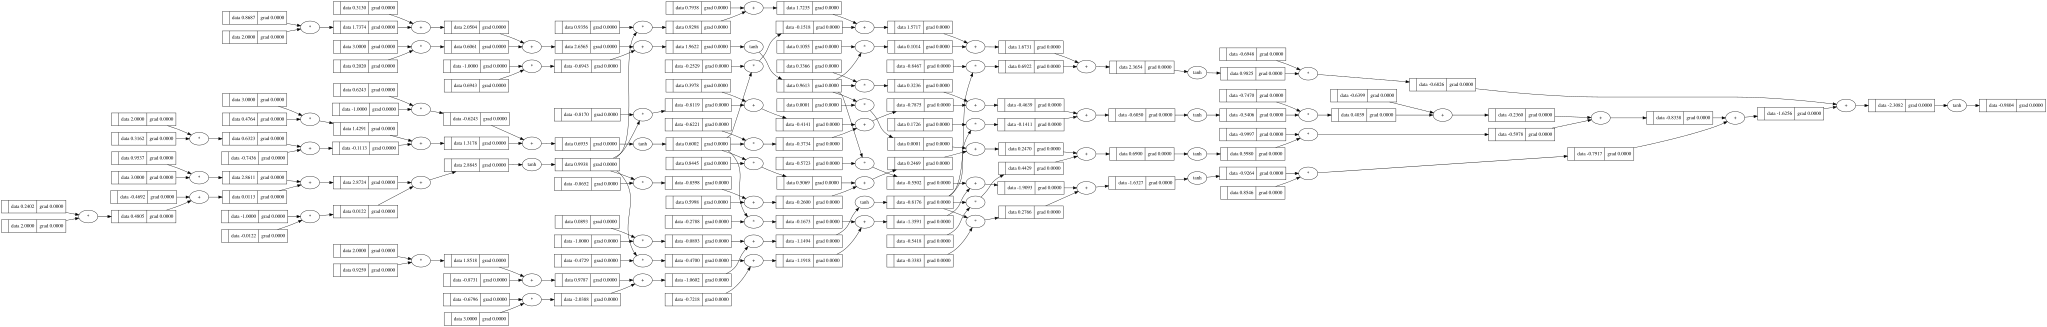

In [119]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)
print(n(x))
print('---')
print('length of parameters: ', len(n.parameters()))
print('---')
print('parameters: ', n.parameters())
draw_dot(n(x))

Gradient Descent

Forward Pass -> Zero Grad -> Back Propagation -> Nudge Parameters

In [120]:
# inputs
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [-2.0, -1.0, -0.5]
]
# desired outputs
ys = [1.0, -1.0, 1.0, -1.0]

In [121]:
# Forward Pass
ypred = [n(x) for x in xs]
print(ypred)
print(ys)

#loss = sum((yout - ygt)**2 for yout, ygt in zip(ys, ypred))
#print(loss)

[Value(data=-0.980415915497201), Value(data=-0.9787643212778195), Value(data=-0.9907715314038219), Value(data=-0.9621936628774523)]
[1.0, -1.0, 1.0, -1.0]


In [128]:
for k in range(50):
  #forward pass
  ypred = [n(x) for x in xs]

  #Loss
  loss = sum((yout - ygt)**2 for yout, ygt in zip(ypred, ys))

  # Zero grad
  for p in n.parameters():
    p.grad = 0.0

  # Back Propagation
  loss.backward()

  # Update / nudge parameters
  for p in n.parameters():
    p.data += -0.1 * p.grad

  print(k, loss.data)

0 0.002241856810635827
1 0.0022240070115851973
2 0.0022064441130619315
3 0.002189161198504843
4 0.002172151572886329
5 0.002155408753887753
6 0.002138926463494043
7 0.0021226986199847377
8 0.002106719330299653
9 0.0020909828827586512
10 0.002075483740116967
11 0.0020602165329375688
12 0.002045176053264196
13 0.002030357248579016
14 0.002015755216030285
15 0.0020013651969156892
16 0.001987182571408497
17 0.0019732028535140965
18 0.001959421686244981
19 0.0019458348370037402
20 0.0019324381931629226
21 0.0019192277578327897
22 0.0019061996458070796
23 0.0018933500796785197
24 0.0018806753861155046
25 0.0018681719922924995
26 0.0018558364224665388
27 0.0018436652946930109
28 0.0018316553176742076
29 0.001819803287734193
30 0.0018081060859143857
31 0.0017965606751840406
32 0.0017851640977604817
33 0.001773913472534048
34 0.0017628059925929483
35 0.0017518389228436185
36 0.0017410095977222115
37 0.0017303154189932494
38 0.0017197538536314412
39 0.0017093224317833431
40 0.0016990187448048355

In [129]:
ypred

[Value(data=0.984194420946835),
 Value(data=-0.9864403335573424),
 Value(data=0.9782731823772937),
 Value(data=-0.9734306812449972)]